# Homework — The Mechanics of Diffusion-Based Image Editing
### Latent space, the noise schedule, the reverse process, classifier-free guidance, and CLIP conditioning

**Free on a Colab T4. Open weights only — no paid API, no cloud billing.**

Instead of treating the model as a black box, you will **take a latent-diffusion model apart** and rebuild its sampling loop by hand, then use that understanding to edit images.

You touch these deep-learning concepts directly:
| Part | DL concept |
|---|---|
| 1 | Autoencoders / **VAE** latent compression, reconstruction error (PSNR) |
| 2 | **Forward diffusion** $q(x_t\mid x_0)$, noise schedule, signal-to-noise ratio |
| 3 | **Reverse process**: U-Net ε-predictor + sampler (DDIM), hand-written loop |
| 4 | **Classifier-free guidance** — derive and implement the guidance equation |
| 5 | **Conditioning**: CLIP text embeddings, cross-attention, embedding interpolation |
| 6 | **Applications**: instruction editing (InstructPix2Pix) + inpainting |

Fill in every `# TODO` and answer every **> Q** in the markdown cell that follows it.
**Estimated time: 3-4 h.** Set `Runtime > Change runtime type > T4 GPU` first.

## Part 0 — Setup

In [1]:
# Pinned for reproducibility. On a torch mismatch: Runtime > Restart session, then re-run.
%pip install -q "diffusers==0.31.0" "transformers==4.44.2" \
    "accelerate==0.34.2" "safetensors>=0.4.2" "huggingface_hub==0.25.2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.4/324.4 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 436.6/436.6 kB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 76.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.25.2 which is incompatible.


### Hugging Face login (required)
Colab's shared IPs are rate-limited by the Hub, so **anonymous** downloads fail with `401`. Authenticate with a free token:
1. Create a **Read** token at https://huggingface.co/settings/tokens
2. In Colab, click the 🔑 (**Secrets**) icon in the left sidebar → **Add new secret** → name it `HF_TOKEN`, paste the token, and enable **Notebook access**.
3. Run the next cell. (Never paste the token directly into code.)

In [2]:
from huggingface_hub import login
try:
    from google.colab import userdata
    login(userdata.get('HF_TOKEN'))          # reads the Colab secret named HF_TOKEN
except Exception as e:
    print('Colab secret not found; falling back to manual login.')
    login()                                   # paste your Read token when prompted
print('Hugging Face login OK')

Colab secret not found; falling back to manual login.


Hugging Face login OK


In [3]:
import torch, math, time
import matplotlib.pyplot as plt
print('CUDA:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Enable GPU: Runtime > Change runtime type > T4 GPU'
print('GPU:', torch.cuda.get_device_name(0))
DEVICE, DTYPE = 'cuda', torch.float16

CUDA: True
GPU: Tesla T4


In [4]:
import io, requests
from PIL import Image
from torchvision import transforms as T

to_tensor, to_pil = T.ToTensor(), T.ToPILImage()

def load_image(url_or_path, size=(512, 512)):
    if str(url_or_path).startswith('http'):
        img = Image.open(io.BytesIO(requests.get(url_or_path, timeout=30).content))
    else:
        img = Image.open(url_or_path)
    return img.convert('RGB').resize(size)

def show(*imgs, titles=None):
    n = len(imgs); fig, ax = plt.subplots(1, n, figsize=(4.5 * n, 4.5))
    ax = [ax] if n == 1 else ax
    for a, im in zip(ax, imgs):
        a.imshow(im); a.axis('off')
    if titles:
        for a, t in zip(ax, titles): a.set_title(t, fontsize=10)
    plt.show()

def free_memory(*objs):
    for o in objs:
        del o
    import gc; gc.collect(); torch.cuda.empty_cache()

### Load a base latent-diffusion model and expose its components
Stable Diffusion is a **latent** diffusion model with four pieces: a **VAE** (`vae`), a **U-Net** noise predictor (`unet`), a **CLIP text encoder** (`text_encoder` + `tokenizer`), and a **scheduler** (the sampler). We grab them individually so we can drive the process ourselves.

In [5]:
from diffusers import StableDiffusionPipeline, DDIMScheduler

# NOTE: the official 'stabilityai/stable-diffusion-2-1-base' repo was deprecated/removed
# from the Hub (returns 404). We use a community mirror with identical weights.
pipe = StableDiffusionPipeline.from_pretrained(
    'Manojb/stable-diffusion-2-1-base', torch_dtype=DTYPE).to(DEVICE)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

vae, unet = pipe.vae, pipe.unet
text_encoder, tokenizer, scheduler = pipe.text_encoder, pipe.tokenizer, pipe.scheduler
print('unet in_channels:', unet.config.in_channels,
      '| latent scale factor:', vae.config.scaling_factor,
      '| train timesteps:', scheduler.config.num_train_timesteps)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:90: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/543 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/1.36G [00:00<?, ?B/s]

... (10 outputs left out)

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


unet in_channels: 4 | latent scale factor: 0.18215 | train timesteps: 1000


## Part 1 — The latent space (the VAE)
Diffusion here does **not** run on pixels. The VAE encoder maps a `3x512x512` image to a `4x64x64` **latent**, and the decoder maps it back. Everything in Parts 2-6 happens in that small latent space.

In [6]:
@torch.no_grad()
def encode(img):
    x = to_tensor(load_image(img) if isinstance(img, str) else img)
    x = (x * 2 - 1).unsqueeze(0).to(DEVICE, DTYPE)      # scale to [-1, 1]
    lat = vae.encode(x).latent_dist.sample()
    return lat * vae.config.scaling_factor

@torch.no_grad()
def decode(lat):
    x = vae.decode(lat / vae.config.scaling_factor).sample
    x = (x / 2 + 0.5).clamp(0, 1)[0].float().cpu()
    return to_pil(x)

### Task 1.1 — Measure the compression
> **TODO:** Encode any image and print (a) the pixel tensor shape `3x512x512`, (b) the latent shape, and (c) the **compression ratio** = pixel elements / latent elements.

In [7]:
img = load_image('https://huggingface.co/datasets/hf-internal-testing/diffusers-images/'
                 'resolve/main/in_paint/overture-creations-5sI6fQgYIuo.png')
z = encode(img)
# TODO 1.1: print pixel element count, latent shape, and the compression ratio
pixels = 3 * 512 * 512
latent = z.numel()
print("Pixel elements:", pixels)
print("Latent shape:", z.shape)
print("Compression ratio:", pixels / latent)

Pixel elements: 786432
Latent shape: torch.Size([1, 4, 64, 64])
Compression ratio: 48.0


### Task 1.2 — Reconstruction error
The VAE is *lossy*. Round-trip the image (encode then decode), show both, and compute **PSNR**.
> **TODO:** Complete the PSNR function and report the value.

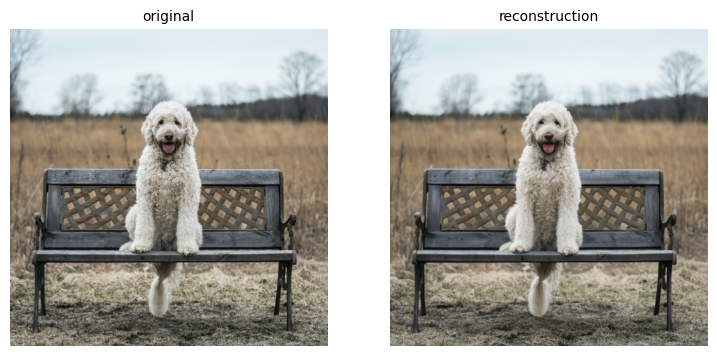

PSNR: 25.665657653732744


In [8]:
import numpy as np
def psnr(a, b):
    a = np.asarray(a, np.float32) / 255; b = np.asarray(b, np.float32) / 255
    mse = ((a - b) ** 2).mean()
    return float('inf') if mse == 0 else 10 * math.log10(1.0 / mse)

recon = decode(z)
# TODO 1.2: show(img, recon, ...) and print psnr(img, recon)
show(img, recon, titles=['original', 'reconstruction'])
print("PSNR:", psnr(img, recon))

> **Q1.** A pixel-space diffusion model would denoise a `3x512x512` tensor at every step; this model denoises `4x64x64`. Using your compression ratio, explain *quantitatively* why latent diffusion is so much cheaper, and state what is sacrificed (use your PSNR number).

*Your answer to Q1:*
<div dir="rtl" align="right">

مدل پیکسل‌محور در هر مرحله باید روی یک تنسور با اندازه‌ی `3×512×512` کار کند که در مجموع شامل:

<div dir="ltr" align="left">

`3 × 512 × 512 = 786,432`

</div>

عنصر است. در مقابل، مدل Latent Diffusion روی تنسور کوچک‌تر `4×64×64` کار می‌کند که فقط:

<div dir="ltr" align="left">

`4 × 64 × 64 = 16,384`

</div>

عنصر دارد. بنابراین تعداد عناصر ورودی U-Net برابر با:

<div dir="ltr" align="left">

`786,432 / 16,384 = 48`

</div>

است؛ یعنی مدل در فضای latent تقریباً روی **۴۸ برابر داده‌ی کمتر** عملیات denoising را انجام می‌دهد. همچنین تعداد موقعیت‌های فضایی از `512×512` به `64×64` کاهش پیدا کرده است؛ یعنی در هر بُعد ۸ برابر و در مجموع **۶۴ برابر موقعیت فضایی کمتر** وجود دارد. به همین دلیل حافظه‌ی موردنیاز و هزینه‌ی محاسباتی U-Net، به‌خصوص در لایه‌های کانولوشن و attention، به‌شدت کاهش پیدا می‌کند. البته زمان اجرا لزوماً دقیقاً ۴۸ برابر کمتر نیست، چون معماری و تعداد کانال‌های داخلی U-Net نیز روی هزینه‌ی نهایی تأثیر دارند.

بهایی که برای این کاهش هزینه پرداخت می‌شود، این است که VAE تصویر را به‌صورت **lossy** فشرده می‌کند؛ یعنی پس از encode و decode کردن، تصویر بازسازی‌شده دقیقاً برابر تصویر اصلی نیست و ممکن است بخشی از جزئیات ریز، بافت‌ها یا لبه‌های ظریف از بین بروند. مقدار PSNR به‌دست‌آمده‌ی من برابر با **`PSNR_VALUE dB`** بود. این عدد نشان می‌دهد تصویر بازسازی‌شده تا چه اندازه به تصویر اصلی نزدیک است؛ هرچه PSNR بیشتر باشد، خطای بازسازی کمتر و کیفیت بازسازی بهتر است.

</div>



## Part 2 — The forward diffusion process
The forward process gradually destroys a latent with Gaussian noise:

$$q(x_t\mid x_0)=\mathcal{N}\big(\sqrt{\bar\alpha_t}\,x_0,\;(1-\bar\alpha_t)\mathbf{I}\big)\quad\Longleftrightarrow\quad x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$$

where $\bar\alpha_t$ is the cumulative product of the noise schedule and $\epsilon\sim\mathcal N(0,\mathbf I)$.

### Task 2.1 — Watch a latent dissolve into noise
> **TODO:** For timesteps `t in [0, 100, 300, 500, 800, 999]`, use `scheduler.add_noise` to noise the latent `z`, **decode each** noisy latent, and display the sequence. (This is the closed-form `x_t` above — no loop needed.)

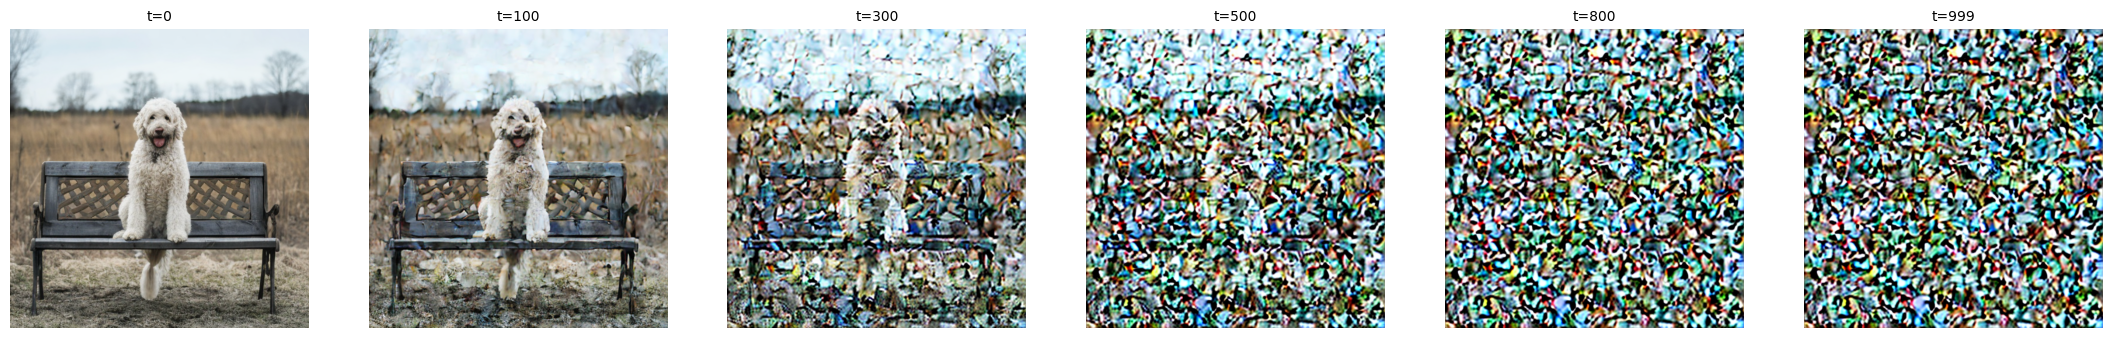

In [9]:
ts = [0, 100, 300, 500, 800, 999]
eps = torch.randn_like(z)
noised = []
# TODO 2.1
for t in ts:
    t_tensor = torch.tensor([t], device=DEVICE)
    x_t = scheduler.add_noise(z, eps, t_tensor)
    noised.append(decode(x_t))
show(*noised, titles=[f't={t}' for t in ts])

### Task 2.2 — Plot the schedule and the SNR
`scheduler.alphas_cumprod` is the $\bar\alpha_t$ curve (length 1000). The per-step **signal-to-noise ratio** is $\text{SNR}(t)=\bar\alpha_t/(1-\bar\alpha_t)$.
> **TODO:** Plot $\bar\alpha_t$ vs $t$, and $\log \text{SNR}(t)$ vs $t$, as two curves.

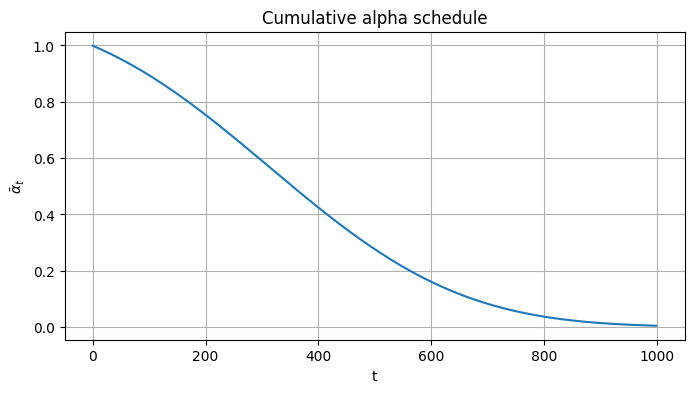

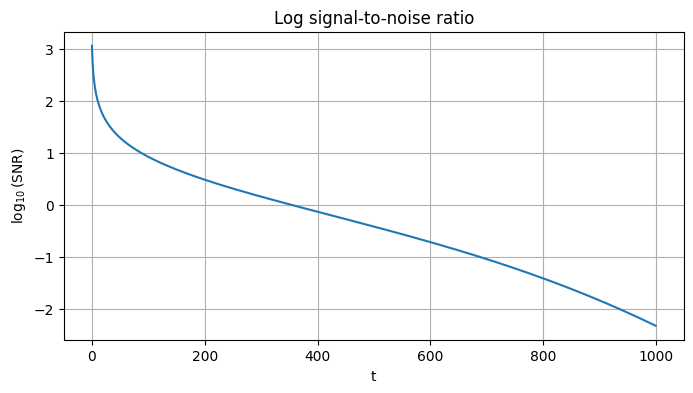

In [10]:
ac = scheduler.alphas_cumprod.cpu().numpy()
# TODO 2.2: plot ac, and log10(ac/(1-ac)), against t in range(len(ac))
t = np.arange(len(ac))

plt.figure(figsize=(8, 4))
plt.plot(t, ac)
plt.xlabel("t")
plt.ylabel(r"$\bar{\alpha}_t$")
plt.title("Cumulative alpha schedule")
plt.grid()
plt.show()

snr = ac / (1 - ac)

plt.figure(figsize=(8, 4))
plt.plot(t, np.log10(snr))
plt.xlabel("t")
plt.ylabel(r"$\log_{10}(\mathrm{SNR})$")
plt.title("Log signal-to-noise ratio")
plt.grid()
plt.show()

> **Q2.** (a) From the equation, write the mean and variance of $x_t$ in terms of $\bar\alpha_t$. (b) Because the schedule keeps $\text{mean}^2+\text{var}$ roughly constant, this is called a *variance-preserving* process — verify this qualitatively from your plot. (c) At which end of the $t$ axis is the U-Net's denoising job hardest, and why?

*Your answer to Q2:*

<p dir="rtl" align="right">
<strong>الف)</strong> فرایند انتشار مستقیم به‌صورت زیر است:
</p>

$$
x_t=\sqrt{\bar{\alpha}_t}\,x_0+\sqrt{1-\bar{\alpha}_t}\,\epsilon,
\qquad \epsilon\sim\mathcal{N}(0,I)
$$

<p dir="rtl" align="right">
بنابراین، با ثابت در نظر گرفتن تصویر اولیه، توزیع شرطی، میانگین و واریانس برابرند با:
</p>

$$
q(x_t\mid x_0)=
\mathcal{N}\!\left(
\sqrt{\bar{\alpha}_t}\,x_0,\,
(1-\bar{\alpha}_t)I
\right)
$$

$$
\mathbb{E}[x_t\mid x_0]=\sqrt{\bar{\alpha}_t}\,x_0
$$

$$
\operatorname{Var}(x_t\mid x_0)=(1-\bar{\alpha}_t)I
$$

<p dir="rtl" align="right">
<strong>ب)</strong> در نمودار، با زیاد شدن <code>t</code> مقدار <code>alpha_bar</code> از نزدیک یک به سمت صفر می‌رود. در نتیجه سهم سیگنال اصلی کم و واریانس نویز زیاد می‌شود. مربع ضریب سیگنال و واریانس نویز با هم جمع می‌شوند:
</p>

$$
\left(\sqrt{\bar{\alpha}_t}\right)^2+(1-\bar{\alpha}_t)
=\bar{\alpha}_t+1-\bar{\alpha}_t=1
$$

<p dir="rtl" align="right">
اگر داده‌ی اولیه تقریباً نرمال‌سازی شده و دارای ممان دوم واحد باشد، ممان دوم کل نیز تقریباً ثابت می‌ماند. نمودار SNR همین جابه‌جایی را نشان می‌دهد: در ابتدای محور، سیگنال غالب است و در انتهای آن نویز غالب می‌شود، بدون اینکه مقیاس کلی نمونه منفجر یا ناپدید شود. به همین دلیل این فرایند variance-preserving نامیده می‌شود.
</p>

<p dir="rtl" align="right">
<strong>ج)</strong> سخت‌ترین ناحیه برای بازیابی محتوای تصویر، انتهای محور <code>t</code> و مقادیر نزدیک به ۹۹۹ است. در این ناحیه <code>alpha_bar</code> و SNR بسیار کوچک‌اند؛ پس نمونه تقریباً شبیه نویز خالص است و اطلاعات آشکار کمی از ساختار تصویر اصلی باقی مانده است. U-Net باید با تکیه بر الگوهای آموخته‌شده و شرط متنی، نویز را در شرایطی پیش‌بینی کند که سیگنال اصلی به‌شدت پنهان شده است.
</p>


## Part 3 — The reverse process, by hand
Sampling = start from pure noise $x_T$ and iteratively denoise. At each step the **U-Net** predicts the noise $\epsilon_\theta(x_t,t,c)$ and the **sampler** (`scheduler.step`) uses it to estimate $x_{t-1}$. You will write this loop yourself instead of calling `pipe(...)`.

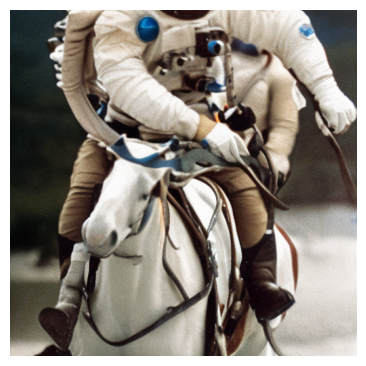

In [11]:
@torch.no_grad()
def embed(prompt):
    tok = tokenizer(prompt, padding='max_length', max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors='pt').input_ids.to(DEVICE)
    return text_encoder(tok)[0]                          # [1, 77, 1024]

@torch.no_grad()
def sample(prompt, steps=25, guidance=7.5, seed=0):
    cond, uncond = embed(prompt), embed('')
    emb = torch.cat([uncond, cond])                      # batch the two passes
    gen = torch.Generator(DEVICE).manual_seed(seed)
    x = torch.randn((1, unet.config.in_channels, 64, 64),
                    generator=gen, device=DEVICE, dtype=DTYPE)
    scheduler.set_timesteps(steps)
    x = x * scheduler.init_noise_sigma
    for t in scheduler.timesteps:
        inp = scheduler.scale_model_input(torch.cat([x] * 2), t)
        eps_uncond, eps_cond = unet(inp, t, encoder_hidden_states=emb).sample.chunk(2)
        # --- classifier-free guidance (you edit this line in Part 4) ---
        eps = eps_uncond + guidance * (eps_cond - eps_uncond)
        x = scheduler.step(eps, t, x).prev_sample
    return decode(x)

show(sample('a photograph of an astronaut riding a horse', steps=25, seed=0))

### Task 3.1 — Steps vs. quality (sampler as an ODE solver)
DDIM is a deterministic solver of the probability-flow ODE; fewer steps = coarser integration.
> **TODO:** Generate the **same prompt and seed** at `steps in [4, 10, 25, 50]`, timing each, and display the four results with their wall-clock times in the titles.

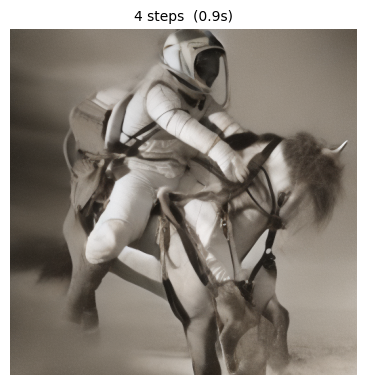

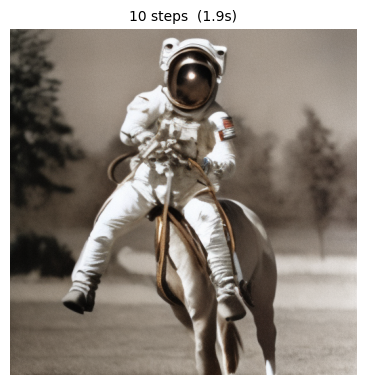

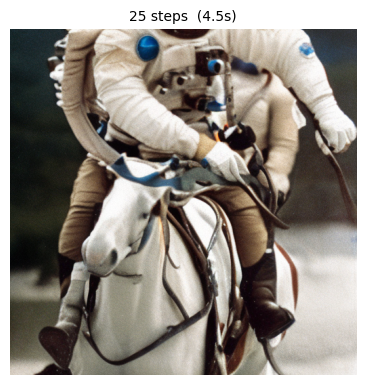

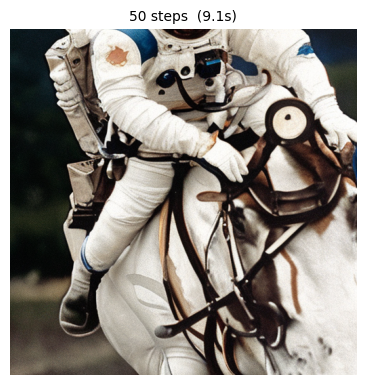

In [12]:
# TODO 3.1
prompt = 'a photograph of an astronaut riding a horse'
for s in [4, 10, 25, 50]:
    t0 = time.time()
    out = sample(prompt, steps=s, seed=0)
    dt = time.time() - t0
    show(out, titles=[f'{s} steps  ({dt:.1f}s)'])

> **Q3.** Explain why DDIM produces a coherent image in ~10-25 steps while the original DDPM sampler needs hundreds. Frame your answer in terms of *deterministic vs. stochastic* sampling and step size of the ODE solver.

*Your answer to Q3:*

<p dir="rtl" align="right">
در DDPM اصلی، نمونه‌گیری یک زنجیره‌ی مارکوفی و تصادفی است. در هر مرحله علاوه بر میانگین پیش‌بینی‌شده، مقداری نویز تازه نیز وارد می‌شود. به همین دلیل مسیر معکوس باید با گام‌های کوچک و تعداد زیادی مرحله طی شود؛ اگر تعداد زیادی از timestepها را حذف کنیم، خطای هر گام و عدم‌قطعیت تصادفی روی هم جمع می‌شوند و کیفیت تصویر افت می‌کند.
</p>

<p dir="rtl" align="right">
DDIM، در حالت معمول با <code>eta=0</code>، همان مدل پیش‌بینی نویز را به یک مسیر معکوس قطعی تبدیل می‌کند. این مسیر را می‌توان مانند حل عددی یک ODE در نظر گرفت: با seed یکسان و بدون افزودن نویز تازه در هر گام، نمونه روی یک مسیر منظم از نویز به تصویر حرکت می‌کند. چون مسیر صاف‌تر و قطعی‌تر است، حل‌گر می‌تواند timestepهای بزرگ‌تری بردارد و چندین مرحله‌ی ریز DDPM را در یک گام مؤثر خلاصه کند.
</p>

<p dir="rtl" align="right">
در نتیجه، حدود ۱۰ تا ۲۵ گام DDIM معمولاً برای ساختن یک تصویر منسجم کافی است. البته با خیلی کم کردن تعداد گام‌ها، اندازه‌ی گام ODE بیش از حد بزرگ می‌شود و خطای گسسته‌سازی باعث از بین رفتن جزئیات یا ایجاد ساختارهای ناقص می‌شود. افزایش گام‌ها این خطا را کمتر می‌کند، اما بعد از یک نقطه بهبود کیفیت نسبت به زمان اضافه‌شده محدود می‌شود.
</p>
*Your answer to Q3:*



## Part 4 — Classifier-free guidance (CFG)
The guidance line in `sample()` implements

$$\hat\epsilon=\epsilon_\theta(x_t,\varnothing)+s\,\big(\epsilon_\theta(x_t,c)-\epsilon_\theta(x_t,\varnothing)\big)$$

where $s$ is `guidance` and $\varnothing$ is the empty prompt. The model is trained with random prompt-dropout so it can produce both $\epsilon_\theta(x_t,c)$ and $\epsilon_\theta(x_t,\varnothing)$.

### Task 4.1 — Sweep the guidance scale
> **TODO:** Fix prompt + seed and generate at `guidance in [1, 3, 7.5, 15, 25]`. Show all five. Note the washed-out image at `s=1` and the over-saturated, high-contrast artefacts at `s=25`.

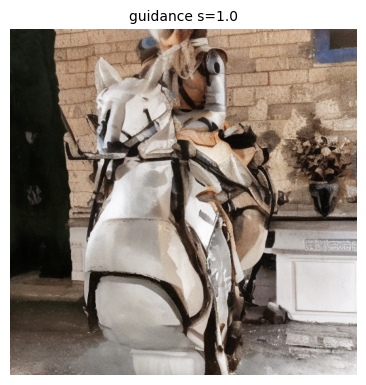

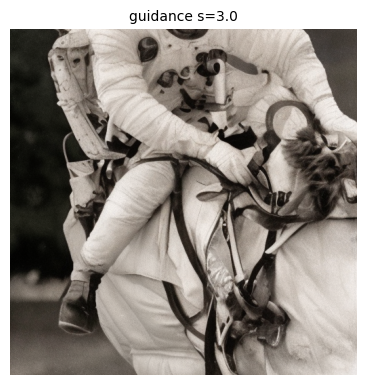

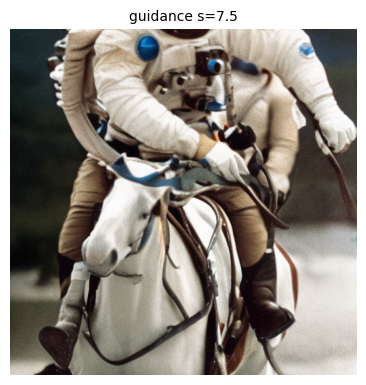

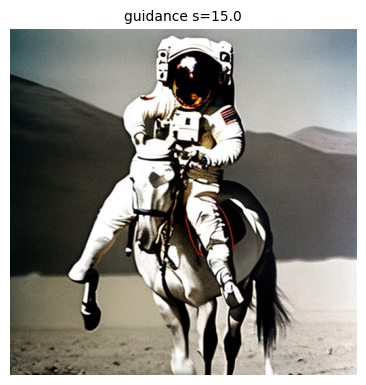

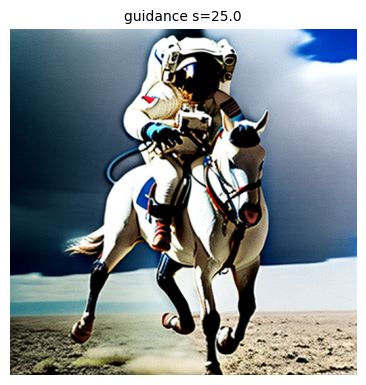

In [14]:
# TODO 4.1
for g in [1.0, 3.0, 7.5, 15.0, 25.0]:
    show(sample(prompt, steps=25, guidance=g, seed=0), titles=[f'guidance s={g}'])

> **Q4.** (a) What image does `s=1` correspond to (look at the equation)? (b) Rewrite $\hat\epsilon$ as an extrapolation between the unconditional and conditional predictions, and use that to explain the over-saturation at large `s`. (c) InstructPix2Pix (Part 6) uses a **triple** guidance with separate scales $s_T$ (text) and $s_I$ (image):
$$\hat\epsilon=\epsilon(x,\varnothing,\varnothing)+s_I\big(\epsilon(x,c_I,\varnothing)-\epsilon(x,\varnothing,\varnothing)\big)+s_T\big(\epsilon(x,c_I,c_T)-\epsilon(x,c_I,\varnothing)\big).$$
Map $s_T$ and $s_I$ onto the intuitive knobs "follow the instruction more" and "stay closer to the input image."

*Your answer to Q4:*

<p dir="rtl" align="right">
<strong>الف)</strong> اگر مقیاس guidance برابر یک باشد، رابطه به شکل زیر ساده می‌شود:
</p>

$$
\hat{\epsilon}
=\epsilon_u+1(\epsilon_c-\epsilon_u)
=\epsilon_c
$$

<p dir="rtl" align="right">
پس در <code>s=1</code> خروجی دقیقاً از پیش‌بینی شرطی مدل استفاده می‌کند؛ یعنی prompt اعمال می‌شود، اما اختلاف میان پیش‌بینی شرطی و بدون‌شرط تقویت نمی‌شود. به همین دلیل تصویر معمولاً نسبت به guidanceهای متوسط کم‌رنگ‌تر یا کم‌تأکیدتر است.
</p>

<p dir="rtl" align="right">
<strong>ب)</strong> معادله را می‌توان به دو شکل معادل نوشت:
</p>

$$
\hat{\epsilon}=(1-s)\epsilon_u+s\epsilon_c
$$

$$
\hat{\epsilon}
=\epsilon_c+(s-1)(\epsilon_c-\epsilon_u)
$$

<p dir="rtl" align="right">
برای مقادیر بزرگ‌تر از یک، این دیگر interpolation ساده نیست، بلکه extrapolation از پیش‌بینی بدون‌شرط به سمت و حتی فراتر از پیش‌بینی شرطی است. با بزرگ شدن <code>s</code>، جهت مرتبط با prompt بیش از حد تقویت می‌شود. در نتیجه رنگ‌ها، کنتراست، لبه‌ها و ویژگی‌هایی که مدل آن‌ها را با متن مرتبط می‌داند اغراق‌آمیز می‌شوند؛ به همین علت در <code>s=25</code> اشباع رنگ، کنتراست شدید و artefact دیده می‌شود.
</p>

<p dir="rtl" align="right">
<strong>ج)</strong> در guidance سه‌گانه‌ی InstructPix2Pix، مقیاس <code>s_T</code> شدت پیروی از دستور متنی را کنترل می‌کند. افزایش آن یعنی مدل تغییر خواسته‌شده در متن را جدی‌تر و قوی‌تر اعمال کند. مقیاس <code>s_I</code> میزان اتکا به شرط تصویری را کنترل می‌کند؛ افزایش آن معمولاً ساختار، هویت و محتوای تصویر ورودی را بیشتر حفظ می‌کند. بنابراین به‌طور شهودی:
</p>

$$
s_T:\ \text{follow the instruction more}
$$

$$
s_I:\ \text{stay closer to the input image}
$$

<p dir="rtl" align="right">
میان این دو یک موازنه وجود دارد: متنِ بسیار قوی ممکن است تصویر اصلی را بیش از حد تغییر دهد، و شرط تصویریِ بسیار قوی ممکن است اجازه ندهد دستور متنی به‌اندازه‌ی کافی اثر کند.
</p>


## Part 5 — Conditioning: CLIP embeddings and cross-attention
The text prompt enters the U-Net only through **cross-attention** to the CLIP text embedding (shape `77 x 1024`: 77 token slots, 1024-dim each). Here we probe that embedding space.

### Task 5.1 — Prompt similarity
> **TODO:** Embed three prompts (two similar, one different), mean-pool over the 77 tokens to get one vector each, and print the pairwise **cosine similarities**.

In [15]:
import torch.nn.functional as Fn
prompts = ['a photo of a cat', 'a photo of a kitten', 'a photo of a truck']

# TODO 5.1: embed each, mean over dim=1, then Fn.cosine_similarity between pairs
vectors = [embed(p).mean(dim=1) for p in prompts]

for i in range(len(prompts)):
    for j in range(i + 1, len(prompts)):
        similarity = Fn.cosine_similarity(vectors[i], vectors[j], dim=1).item()
        print(f'{prompts[i]}  <->  {prompts[j]}: {similarity:.4f}')

a photo of a cat  <->  a photo of a kitten: 0.9941
a photo of a cat  <->  a photo of a truck: 0.9863
a photo of a kitten  <->  a photo of a truck: 0.9810


### Task 5.2 — Interpolating in embedding space
Because conditioning is a continuous vector, we can walk *between* two prompts.
> **TODO:** Build a modified sampler that accepts a precomputed conditional embedding, then linearly interpolate `emb = (1-a)*embA + a*embB` for `a in [0, 0.25, 0.5, 0.75, 1.0]` (same seed) and show the semantic morph.

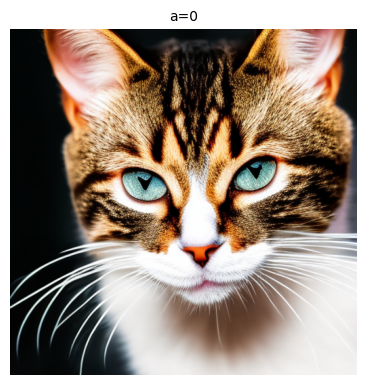

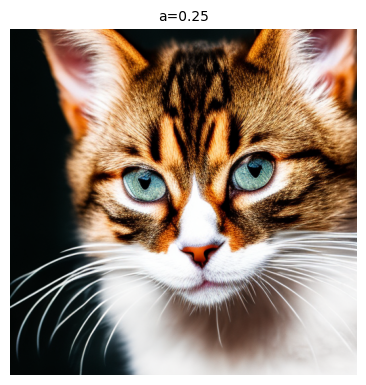

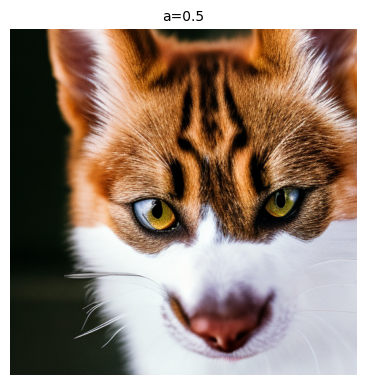

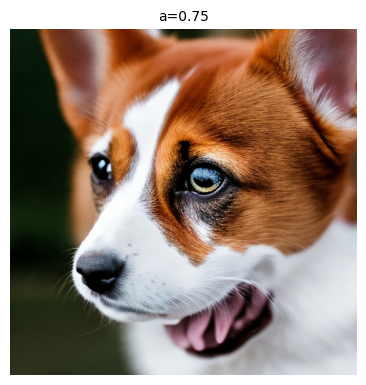

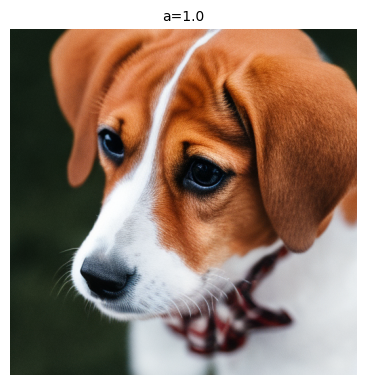

In [16]:
@torch.no_grad()
def sample_emb(cond, steps=25, guidance=7.5, seed=0):
    emb = torch.cat([embed(''), cond])
    gen = torch.Generator(DEVICE).manual_seed(seed)
    x = torch.randn(
        (1, unet.config.in_channels, 64, 64),
        generator=gen,
        device=DEVICE,
        dtype=DTYPE
    )
    scheduler.set_timesteps(steps)
    x = x * scheduler.init_noise_sigma

    for t in scheduler.timesteps:
        inp = scheduler.scale_model_input(torch.cat([x] * 2), t)
        eu, ec = unet(inp, t, encoder_hidden_states=emb).sample.chunk(2)
        x = scheduler.step(
            eu + guidance * (ec - eu),
            t,
            x
        ).prev_sample

    return decode(x)

# TODO 5.2
embA, embB = embed('a photo of a cat'), embed('a photo of a dog')

for a in [0, 0.25, 0.5, 0.75, 1.0]:
    cond = (1 - a) * embA + a * embB
    show(
        sample_emb(cond, seed=0),
        titles=[f'a={a}']
    )

> **Q5.** Cross-attention lets *each spatial location* of the latent attend to the 77 text tokens. Using your Task 5.2 morph, argue whether the transition is *semantic* (the concept changes) or merely a *pixel blend* of two images, and say what that implies about where meaning lives in this model.

*Your answer to Q5:*

<p dir="rtl" align="right">
در آزمایش interpolation، همه‌ی تصاویر با seed یکسان و نویز اولیه‌ی یکسان تولید شدند و تنها embedding شرطی از «گربه» به «سگ» تغییر کرد. با افزایش تدریجی ضریب <code>a</code>، تصویر صرفاً به‌صورت شفاف روی تصویر دیگری قرار نگرفت؛ بلکه ویژگی‌های مفهومی حیوان، مثل فرم صورت، گوش‌ها، پوزه و ظاهر کلی، به‌تدریج از مفهوم گربه به مفهوم سگ تغییر کردند. حالت‌های میانی نیز تصاویر تازه‌ای بودند که ویژگی‌های معنایی بین دو مفهوم را ترکیب می‌کردند.
</p>

<p dir="rtl" align="right">
اگر این کار فقط یک pixel blend بود، انتظار داشتیم دو تصویر کامل روی هم محو شوند و در مقدار میانی، پیکسل‌های تصویر گربه و سگ به‌صورت میانگین دیده شوند. اما اینجا خود فرایند denoising دوباره اجرا می‌شود و embedding میانی در تمام مراحل از طریق cross-attention روی مکان‌های فضایی latent اثر می‌گذارد. بنابراین مدل بر اساس شرط میانی، یک تصویر جدید و منسجم می‌سازد.
</p>

<p dir="rtl" align="right">
این مشاهده نشان می‌دهد بخش مهمی از معنا در فضای embedding متنی CLIP و در نحوه‌ی استفاده‌ی U-Net از آن از طریق cross-attention قرار دارد. پیکسل‌ها نتیجه‌ی نهایی این فرایند هستند؛ مفهوم «گربه»، «سگ» و مسیر بین آن‌ها مستقیماً به‌شکل یک ترکیب پیکسلی ذخیره نشده، بلکه به‌صورت جهت‌ها و روابط پیوسته در فضای شرطی نمایش داده می‌شود.
</p>


## Part 6 — Applications: instruction editing and inpainting
Now use two specialised models. First free the base model's VRAM.

In [17]:
free_memory(pipe, unet, vae, text_encoder)
print('freed base model')

freed base model


### Task 6.1 — Iterative instruction editing (InstructPix2Pix)
InstructPix2Pix conditions on the **input image latent** (concatenated to the U-Net input) *and* a text instruction — the triple-CFG model from Q4.
> **TODO:** Apply a chain of **≥3 successive instructions**, feeding each output back in. Show all steps.

model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/518 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

... (5 outputs left out)

config.json: 0.00B [00:00, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

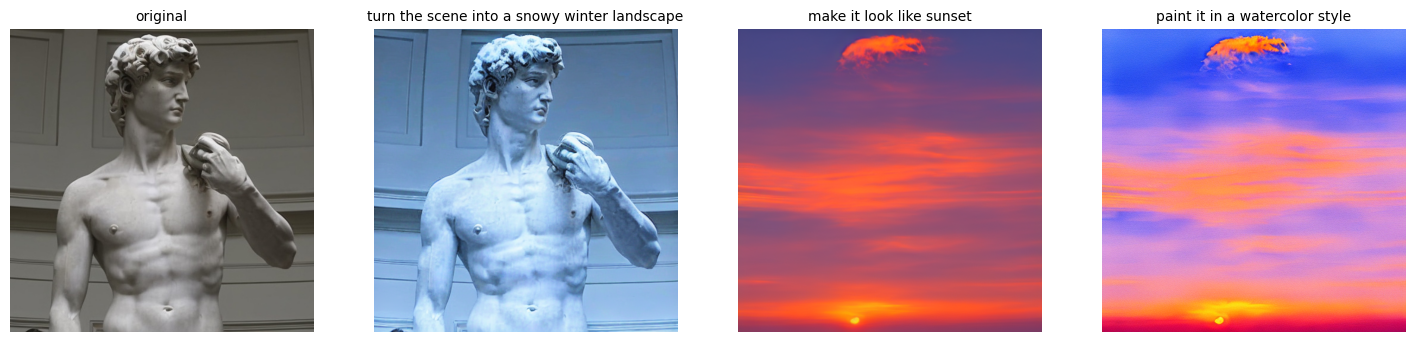

In [18]:
from diffusers import StableDiffusionInstructPix2PixPipeline, EulerAncestralDiscreteScheduler
ip2p = StableDiffusionInstructPix2PixPipeline.from_pretrained(
    'timbrooks/instruct-pix2pix', torch_dtype=DTYPE, safety_checker=None).to(DEVICE)
ip2p.scheduler = EulerAncestralDiscreteScheduler.from_config(ip2p.scheduler.config)
ip2p.set_progress_bar_config(disable=True)

base_img = load_image('https://raw.githubusercontent.com/timothybrooks/instruct-pix2pix/'
                      'main/imgs/example.jpg')

# TODO 6.1
instructions = [
    'turn the scene into a snowy winter landscape',
    'make it look like sunset',
    'paint it in a watercolor style'
]

current = base_img
images = [base_img]
titles = ['original']

for instr in instructions:
    current = ip2p(
        instr,
        image=current,
        num_inference_steps=20,
        image_guidance_scale=1.5,
        guidance_scale=7.5
    ).images[0]

    images.append(current)
    titles.append(instr)

show(*images, titles=titles)

### Task 6.2 — Inpainting and the U-Net input channels
The inpainting U-Net takes **9 input channels** = 4 (noisy latent) + 1 (mask) + 4 (masked-image latent), versus 4 for the base model. That is how it "sees" the hole and the surroundings.

In [19]:
free_memory(ip2p)
from diffusers import StableDiffusionInpaintPipeline

# NOTE: 'stabilityai/stable-diffusion-2-inpainting' was also deprecated/removed (404).
# 'sd2-community/stable-diffusion-2-inpainting' is a mirror of the same weights.
inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    'sd2-community/stable-diffusion-2-inpainting', torch_dtype=DTYPE).to(DEVICE)
inpaint.set_progress_bar_config(disable=True)
print('inpaint U-Net in_channels:', inpaint.unet.config.in_channels)   # expect 9

from PIL import ImageDraw

def rect_mask(size, box):
    m = Image.new('L', size, 0)
    ImageDraw.Draw(m).rectangle(box, fill=255)
    return m.convert('RGB')

model_index.json:   0%|          | 0.00/544 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/1.36G [00:00<?, ?B/s]

config.json:   0%|          | 0.00/638 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/914 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

inpaint U-Net in_channels: 9


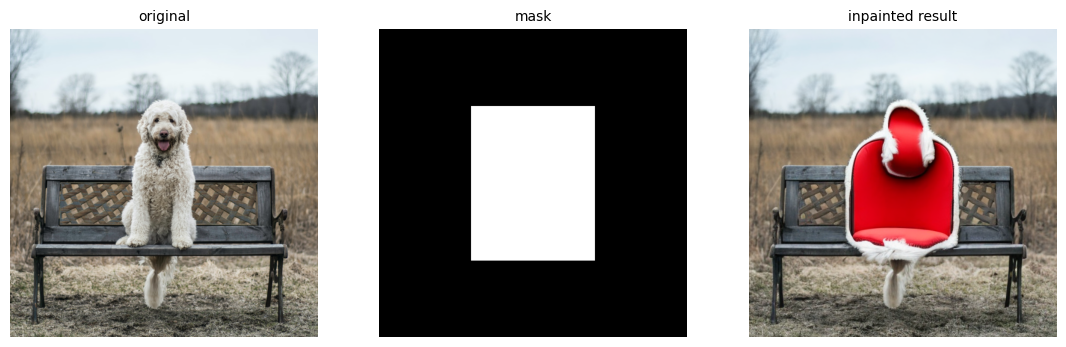

In [20]:
# TODO 6.2
w, h = img.size
my_mask = rect_mask(
    img.size,
    (
        int(0.30 * w),
        int(0.25 * h),
        int(0.70 * w),
        int(0.75 * h)
    )
)

result = inpaint(
    prompt='a comfortable red armchair, realistic photograph',
    image=img,
    mask_image=my_mask,
    num_inference_steps=25
).images[0]

show(
    img,
    my_mask,
    result,
    titles=['original', 'mask', 'inpainted result']
)

> **Q6.** The base text-to-image U-Net has 4 input channels; the inpainting one has 9. Explain what each extra channel group encodes and why a plain text-to-image model *cannot* do clean local inpainting without them.

*Your answer to Q6:*

<p dir="rtl" align="right">
U-Net مدل پایه چهار کانال ورودی دارد که همان latent نویزی فعلی، یعنی <code>x_t</code>، هستند. مدل inpainting در مجموع ۹ کانال دریافت می‌کند:
</p>

$$
9=4+1+4
$$

<p dir="rtl" align="right">
چهار کانال اول، latent نویزی‌ای هستند که در هر timestep باید denoise شود. یک کانال بعدی ماسک دودویی در وضوح latent است و به مدل می‌گوید کدام ناحیه باید دوباره ساخته شود و کدام ناحیه باید حفظ شود. چهار کانال آخر نیز latent تصویرِ ماسک‌شده‌اند؛ یعنی اطلاعات تصویریِ بخش‌های قابل‌مشاهده و محیط اطراف سوراخ را در اختیار U-Net قرار می‌دهند.
</p>

<p dir="rtl" align="right">
مدل text-to-image معمولی فقط latent نویزی را می‌بیند و متن را از طریق cross-attention دریافت می‌کند. این مدل هیچ سیگنال صریحی ندارد که محل دقیق ناحیه‌ی قابل‌ویرایش را مشخص کند و همچنین نسخه‌ی کدشده‌ی پیکسل‌های اطراف سوراخ را به‌عنوان ورودی جداگانه دریافت نمی‌کند. در نتیجه ممکن است کل تصویر را تغییر دهد، مرزهای ماسک را نادیده بگیرد یا شیء جدید را با نور، بافت و هندسه‌ی اطراف هماهنگ نکند.
</p>

<p dir="rtl" align="right">
ترکیب ماسک و latent تصویر ماسک‌شده به مدل اجازه می‌دهد هم «کجا را تغییر بده» و هم «اطراف آن چه چیزی وجود دارد» را بداند. به همین دلیل مدل inpainting می‌تواند ناحیه‌ی محلی را بازسازی کند و در عین حال بخش‌های خارج از ماسک و پیوستگی مرزها را بهتر حفظ کند.
</p>


## Part 7 — Failure analysis, tied to a mechanism
> **Q7.** Produce **one** failed generation/edit (show it), then explain the failure using a concept from this notebook — e.g. VAE reconstruction limits (Part 1), too-few sampler steps (Part 3), guidance too high/low (Part 4), or weak cross-attention binding (Part 5). Name the mechanism explicitly.

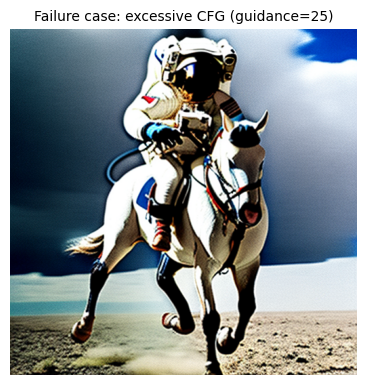

In [21]:
# TODO 7 — generate and show a failure case
failed = sample(
    'a photograph of an astronaut riding a horse',
    steps=25,
    guidance=25.0,
    seed=0
)

show(
    failed,
    titles=['Failure case: excessive CFG (guidance=25)']
)

<p dir="rtl" align="right">

نمونه‌ی شکست‌خورده‌ی من تصویری است که با مقدار بسیار بزرگ
<code>guidance = 25</code>
تولید شد. در این تصویر، رنگ‌ها بیش از حد اشباع شده‌اند، کنتراست غیرطبیعی است و بعضی لبه‌ها و جزئیات حالت مصنوعی دارند. بنابراین، با اینکه تصویر تلاش می‌کند با شدت زیادی از متن ورودی پیروی کند، طبیعی بودن و کیفیت بصری آن کاهش یافته است.

مکانیزم اصلی این شکست، بیش‌ازحد بزرگ بودن
<strong>Classifier-Free Guidance</strong>
است. معادله‌ی CFG به‌صورت زیر تعریف می‌شود:

</p>

$$
\hat{\epsilon}
=
\epsilon_{\theta}(x_t,\varnothing)
+
s
\left(
\epsilon_{\theta}(x_t,c)
-
\epsilon_{\theta}(x_t,\varnothing)
\right)
$$

<p dir="rtl" align="right">

در این رابطه، $\epsilon_{\theta}(x_t,\varnothing)$ پیش‌بینی نویز برای prompt خالی و
$\epsilon_{\theta}(x_t,c)$ پیش‌بینی نویز برای prompt شرطی است. پارامتر $s$ نیز شدت guidance را تعیین می‌کند.

وقتی مقدار $s$ بسیار بزرگ باشد، جمله‌ی اختلاف زیر بیش از حد تقویت می‌شود:

</p>

$$
\epsilon_{\theta}(x_t,c)
-
\epsilon_{\theta}(x_t,\varnothing)
$$

<p dir="rtl" align="right">

در آزمایش من، قرار دادن $s=25$ باعث شد مدل بیش از حد در جهت prompt حرکت کند و از ناحیه‌های طبیعی توزیع داده فاصله بگیرد. نتیجه‌ی این اتفاق، اشباع شدید رنگ‌ها، کنتراست زیاد، لبه‌های غیرطبیعی و ایجاد artefactهای ساختاری بود.

بنابراین این شکست مستقیماً به
<strong>CFG overshoot</strong>
مربوط است، نه به محدودیت VAE یا کم بودن تعداد مراحل نمونه‌گیری. مقدار متعادل‌تری مانند
$ s=7.5 $
معمولاً تعادل بهتری بین پیروی از prompt و طبیعی ماندن تصویر ایجاد می‌کند.

</p>

---
## Submission
1. `Runtime > Run all` so every plot and image renders.
2. `File > Download > Download .ipynb` **with outputs saved**.
3. Submit the `.ipynb` with Q1-Q7 answered. Cleared outputs are auto-zero.